# Facial Emotion Recognition

A compact TensorFlow/Keras CNN for the seven expression classes in FRE_dataset. Images are 48×48 grayscale face crops. The notebook trains on train/, reserves 15% of it for validation, and reports final results on test/.

Select the TensorFlow VENV kernel, then run setup, data loading, model training, and evaluation. The final cell starts a local OpenCV webcam demo when RUN_WEBCAM is changed to True. Webcam access requires running Jupyter on the computer with the camera.

The displayed confidence is the model's highest softmax score. It is useful for comparing predictions, but it is not a calibrated probability that the person feels that emotion.


In [1]:
from pathlib import Path
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_DIR = Path.cwd() / "FRE_dataset"
if not (DATA_DIR / "train").is_dir() or not (DATA_DIR / "test").is_dir():
    raise FileNotFoundError(f"Expected FRE_dataset/train and FRE_dataset/test under {Path.cwd()}")

IMAGE_SIZE = (48, 48)
BATCH_SIZE = 64
VALIDATION_SPLIT = 0.15
EPOCHS = 45
TRAIN_MODEL = False  # Set True to retrain; default loads the trained checkpoint.
MODEL_PATH = Path.cwd() / "emotion_cnn.keras"

print("TensorFlow:", tf.__version__)
print("Dataset:", DATA_DIR.resolve())


TensorFlow: 2.21.0
Dataset: /Users/akhilesh/Desktop/DL_project/FRE_dataset


## Load the images

The data is imbalanced, especially disgust. Inverse-frequency class weights give less common classes more influence while training. Validation is sampled only from train; test stays untouched until final evaluation.


In [2]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    labels="inferred",
    label_mode="int",
    color_mode="grayscale",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    subset="training",
    seed=SEED,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    labels="inferred",
    label_mode="int",
    color_mode="grayscale",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    subset="validation",
    seed=SEED,
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    labels="inferred",
    label_mode="int",
    color_mode="grayscale",
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_names = train_ds.class_names
assert class_names == val_ds.class_names == test_ds.class_names
print("Classes:", class_names)

# Count supported image files directly in each class directory.
image_suffixes = {".jpg", ".jpeg", ".png", ".bmp"}
train_counts = {
    name: sum(p.suffix.lower() in image_suffixes for p in (DATA_DIR / "train" / name).iterdir())
    for name in class_names
}
total_train = sum(train_counts.values())
class_weights = {
    i: total_train / (len(class_names) * train_counts[name])
    for i, name in enumerate(class_names)
}
print("Training images:", train_counts)
print("Class weights:", {name: round(class_weights[i], 2) for i, name in enumerate(class_names)})

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


Found 28709 files belonging to 7 classes.
Using 24403 files for training.
Found 28709 files belonging to 7 classes.
Using 4306 files for validation.
Found 7178 files belonging to 7 classes.
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Training images: {'angry': 3995, 'disgust': 436, 'fear': 4097, 'happy': 7215, 'neutral': 4965, 'sad': 4830, 'surprise': 3171}
Class weights: {'angry': 1.03, 'disgust': 9.41, 'fear': 1.0, 'happy': 0.57, 'neutral': 0.83, 'sad': 0.85, 'surprise': 1.29}


## Build the lightweight CNN

Small augmentation and weight decay help generalization. The model includes grayscale normalization, so the webcam demo can pass OpenCV crops in the same 0–255 pixel range as the dataset.


In [3]:
from tensorflow.keras import layers, regularizers

augment = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.04),
        layers.RandomTranslation(0.04, 0.04),
        layers.RandomZoom(0.08),
    ],
    name="augmentation",
)

inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 1), name="face")
x = augment(inputs)
x = layers.Rescaling(1.0 / 255)(x)

for filters, dropout_rate in [(32, 0.15), (64, 0.20), (128, 0.25)]:
    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4),
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4),
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4))(x)
x = layers.Dropout(0.35)(x)
outputs = layers.Dense(len(class_names), activation="softmax", name="expression_scores")(x)
model = tf.keras.Model(inputs, outputs, name="emotion_cnn")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)
model.summary()


Model: "emotion_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ face (InputLayer)               │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 305,191 (1.16 MB)

 Trainable params: 304,295 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

## Train or load the saved checkpoint

The trained checkpoint is included, so the default run loads it and goes straight to test evaluation and webcam use. Set TRAIN_MODEL = True in the setup cell to retrain; full training can take a while on CPU.


In [4]:
if TRAIN_MODEL:
    # Resume from the delivered checkpoint when one exists; otherwise start fresh.
    if MODEL_PATH.is_file():
        model = tf.keras.models.load_model(MODEL_PATH)
        _, checkpoint_threshold = model.evaluate(val_ds, verbose=0)
        print(f"Resuming from checkpoint (val accuracy: {checkpoint_threshold:.3f})")
    else:
        checkpoint_threshold = None

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            MODEL_PATH, monitor="val_accuracy", mode="max",
            save_best_only=True, initial_value_threshold=checkpoint_threshold,
            verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", mode="max", patience=9,
            restore_best_weights=True, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=3,
            min_lr=1e-5, verbose=1,
        ),
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        class_weight=class_weights,
        callbacks=callbacks,
    )
    model = tf.keras.models.load_model(MODEL_PATH)
    print(f"Best model saved to: {MODEL_PATH.resolve()}")
else:
    if not MODEL_PATH.is_file():
        raise FileNotFoundError(f"Trained model not found: {MODEL_PATH}. Set TRAIN_MODEL = True first.")
    model = tf.keras.models.load_model(MODEL_PATH)
    print(f"Loaded trained checkpoint: {MODEL_PATH.resolve()}")


Loaded trained checkpoint: /Users/akhilesh/Desktop/DL_project/emotion_cnn.keras


In [5]:
if TRAIN_MODEL:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history.history["accuracy"], label="train")
    axes[0].plot(history.history["val_accuracy"], label="validation")
    axes[0].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[0].legend()
    axes[1].plot(history.history["loss"], label="train")
    axes[1].plot(history.history["val_loss"], label="validation")
    axes[1].set(title="Loss", xlabel="Epoch", ylabel="Loss")
    axes[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print("Loaded a trained checkpoint; training curves are shown after retraining.")


Loaded a trained checkpoint; training curves are shown after retraining.


## Evaluate on the held-out test set

Accuracy gives the overall hit rate; macro F1 gives each expression equal weight. Per-class scores and the confusion matrix reveal where the model is weaker.


Test accuracy: 0.537
Test cross-entropy: 1.211
              precision    recall  f1-score   support

       angry      0.379     0.604     0.466       958
     disgust      0.731     0.171     0.277       111
        fear      0.461     0.110     0.178      1024
       happy      0.895     0.684     0.775      1774
     neutral      0.428     0.740     0.542      1233
         sad      0.482     0.273     0.348      1247
    surprise      0.575     0.819     0.676       831

    accuracy                          0.537      7178
   macro avg      0.564     0.486     0.466      7178
weighted avg      0.573     0.537     0.515      7178



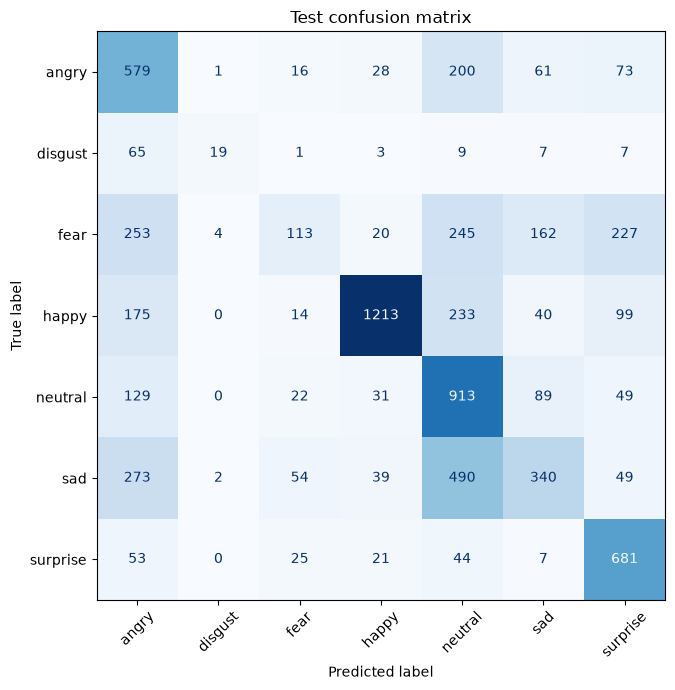

In [6]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# One inference pass over test is enough for accuracy, loss, report, and matrix.
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
probabilities = model.predict(test_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)
test_accuracy = float(np.mean(y_pred == y_true))
test_loss = float(np.mean(
    tf.keras.losses.sparse_categorical_crossentropy(y_true, probabilities).numpy()
))

print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test cross-entropy: {test_loss:.3f}")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
)
ax.set_title("Test confusion matrix")
plt.tight_layout()
plt.show()


## Live webcam demo with OpenCV

Set RUN_WEBCAM to True and run this cell. Press q in the video window to close it. Haar cascade detection and the compact CNN keep the demo self-contained.


In [1]:
import cv2

RUN_WEBCAM = False  # Change to True to start the camera.
if RUN_WEBCAM:
    cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
    detector = cv2.CascadeClassifier(cascade_path)
    if detector.empty():
        raise RuntimeError(f"Could not load face detector: {cascade_path}")

    camera = cv2.VideoCapture(0)
    if not camera.isOpened():
        camera.release()
        raise RuntimeError("Could not open camera 0. Check camera permissions or try another camera index.")

    smoothed_scores = None
    try:
        while True:
            ok, frame = camera.read()
            if not ok:
                print("Could not read a webcam frame.")
                break

            frame = cv2.flip(frame, 1)
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            faces = detector.detectMultiScale(
                gray, scaleFactor=1.1, minNeighbors=5, minSize=(48, 48)
            )

            if len(faces) == 0:
                smoothed_scores = None
            else:
                # Follow the largest detected face.
                x, y, w, h = max(faces, key=lambda box: box[2] * box[3])
                face = cv2.resize(gray[y:y+h, x:x+w], IMAGE_SIZE, interpolation=cv2.INTER_AREA)
                scores = model.predict(face[np.newaxis, ..., np.newaxis], verbose=0)[0]
                smoothed_scores = scores if smoothed_scores is None else 0.7 * smoothed_scores + 0.3 * scores

                best_index = int(np.argmax(smoothed_scores))
                label = class_names[best_index]
                confidence = float(smoothed_scores[best_index]) * 100
                color = (40, 210, 40) if confidence >= 55 else (0, 190, 255)

                cv2.rectangle(frame, (x, y), (x + w, y + h), color, 2)
                cv2.rectangle(frame, (x, max(0, y - 32)), (x + w, y), color, -1)
                cv2.putText(
                    frame, f"{label}: {confidence:.0f}%",
                    (x + 6, max(22, y - 9)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.65, (20, 20, 20), 2, cv2.LINE_AA,
                )

            cv2.imshow("Facial expression recognition | press q to quit", frame)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
    finally:
        camera.release()
        cv2.destroyAllWindows()
